In [76]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report,mean_squared_error,r2_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import streamlit as st
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


#### 1- Train Data

In [77]:
df = pd.read_csv('train.csv')

df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]

numerical_features =["GrLivArea","OverallQual","YearBuilt","TotalSF","HouseAge","GarageCars","LotArea"]

categorical_features = ["Neighborhood","MSZoning","Exterior1st","KitchenQual"]

features = numerical_features + categorical_features

x = df[features]
y = df["SalePrice"]


x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)


In [78]:
numerical_transformer = Pipeline(steps=[
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("onehot",OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num",numerical_transformer,numerical_features),
        ("cat",categorical_transformer,categorical_features)
    ]
)


model_pipeline = Pipeline(steps=[
    ("preprocessor",preprocessor),
    ("model",XGBRegressor(n_estimators=150,learning_rate=0.08,max_depth=5,random_state=42))
])


In [79]:
model_pipeline.fit(x_train,y_train)
y_pred = model_pipeline.predict(x_test)

MSE =np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {MSE:.2f}")
print(f"R2 Score: {r2*100:.2f}%")

Mean Squared Error: 26614.73
R2 Score: 90.77%


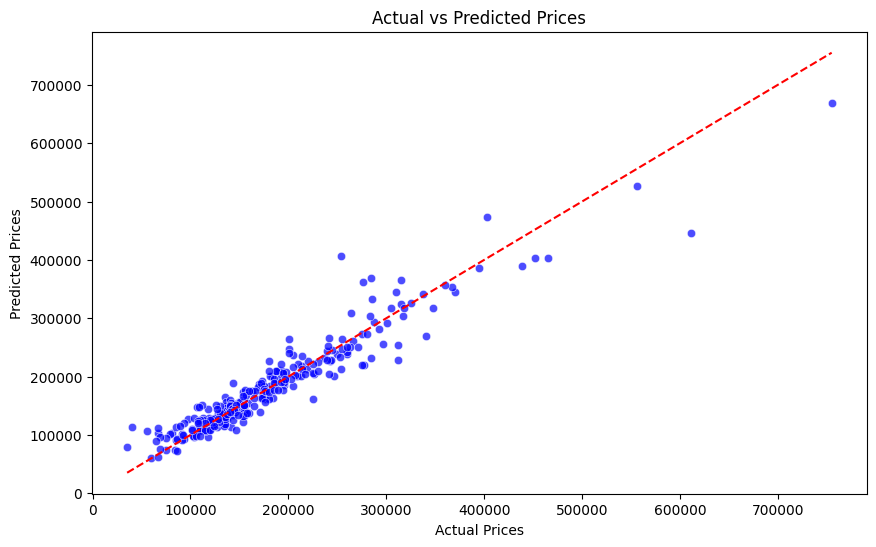

In [80]:
plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test,y=y_pred,alpha=0.7,color="blue")
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],"r--")
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Prices")
plt.show()






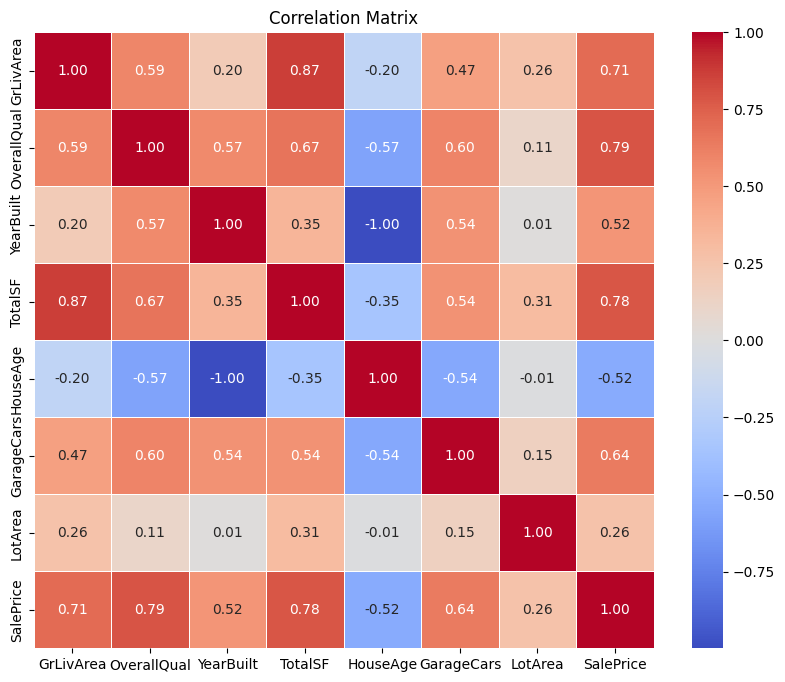

In [81]:
plt.figure(figsize=(10,8))
corr_matrix = df[numerical_features + ["SalePrice"]].corr()
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm",fmt=".2f",linewidths=0.5)
plt.title("Correlation Matrix")
plt.show()

In [82]:
import joblib

# حفظ الـ Pipeline المدرب بالكامل في ملف
joblib.dump(model_pipeline, 'house_price_model.pkl')
print("sucseefuly saved house_price_model.pkl!")

sucseefuly saved house_price_model.pkl!
